In [5]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import getpass
from pathlib import Path
from typing import Any, Optional, Tuple

from sentinelhub import (
    SHConfig,
    DataCollection,
    SentinelHubCatalog,
    SentinelHubRequest,
    SentinelHubStatistical,
    BBox,
    bbox_to_dimensions,
    CRS,
    MimeType,
    Geometry,
)

def plot_image(
    image: np.ndarray,
    factor: float = 1.0,
    clip_range: Optional[Tuple[float, float]] = None,
    **kwargs: Any
) -> None:
    """Utility function for plotting RGB images."""
    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(15, 15))
    if clip_range is not None:
        ax.imshow(np.clip(image * factor, *clip_range), **kwargs)
    else:
        ax.imshow(image * factor, **kwargs)
    ax.set_xticks([])
    ax.set_yticks([])

In [6]:
config = SHConfig('Teledeteccion')

In [7]:
aoi_coords_wgs84 = [-7.04641, 36.42570, -6.04641, 37.42570] # Coordenadas (latitud y longitud) de esquina 
                                                            # inferior izquierda y esquina superior derecha.
resolution = 100                                            # Resolución en metros
aoi_bbox = BBox(bbox=aoi_coords_wgs84, crs=CRS.WGS84)
aoi_size = bbox_to_dimensions(aoi_bbox, resolution=resolution)

print(f"Image shape at {resolution} m resolution: {aoi_size} pixels") # Para el ejemplo, de 1100x1100 px

Image shape at 100 m resolution: (862, 1133) pixels


In [8]:
catalog = SentinelHubCatalog(config=config)

aoi_bbox = BBox(bbox=aoi_coords_wgs84, crs=CRS.WGS84)
time_interval = "2024-05-01", "2024-05-31"

search_iterator = catalog.search(
    DataCollection.SENTINEL2_L2A, #Selección de satélite y categoría
    bbox=aoi_bbox,
    time=time_interval,
    fields={"include": ["id", "properties.datetime"], "exclude": []},
)

results = list(search_iterator)
print("Total number of results:", len(results))

results


Total number of results: 42


[{'id': 'S2B_MSIL2A_20240530T110619_N0510_R137_T29SPA_20240530T135208.SAFE',
  'properties': {'datetime': '2024-05-30T11:21:13.247Z'}},
 {'id': 'S2B_MSIL2A_20240530T110619_N0510_R137_T29SQA_20240530T135208.SAFE',
  'properties': {'datetime': '2024-05-30T11:21:10.222Z'}},
 {'id': 'S2B_MSIL2A_20240530T110619_N0510_R137_T30STF_20240530T135208.SAFE',
  'properties': {'datetime': '2024-05-30T11:21:08.763Z'}},
 {'id': 'S2B_MSIL2A_20240530T110619_N0510_R137_T29SPB_20240530T135208.SAFE',
  'properties': {'datetime': '2024-05-30T11:20:58.773Z'}},
 {'id': 'S2B_MSIL2A_20240530T110619_N0510_R137_T29SQB_20240530T135208.SAFE',
  'properties': {'datetime': '2024-05-30T11:20:55.658Z'}},
 {'id': 'S2B_MSIL2A_20240530T110619_N0510_R137_T30STG_20240530T135208.SAFE',
  'properties': {'datetime': '2024-05-30T11:20:54.428Z'}},
 {'id': 'S2A_MSIL2A_20240528T112121_N0510_R037_T29SPB_20240528T164850.SAFE',
  'properties': {'datetime': '2024-05-28T11:30:56.108Z'}},
 {'id': 'S2A_MSIL2A_20240525T110621_N0510_R137_T

In [9]:
evalscript_true_color = """
    //VERSION=3

    function setup() {
        return {
            input: [{
                bands: ["B02", "B03", "B04"]
            }],
            output: {
                bands: 3
            }
        };
    }

    function evaluatePixel(sample) {
        return [sample.B04, sample.B03, sample.B02];
    }
"""

request_true_color = SentinelHubRequest(
    evalscript=evalscript_true_color,
    input_data=[
        SentinelHubRequest.input_data(
            data_collection=DataCollection.SENTINEL2_L2A.define_from(
                name="s2l2a", service_url="https://sh.dataspace.copernicus.eu"
            ),
            time_interval=("2024-05-01", "2024-05-31"),
            other_args={"dataFilter": {"mosaickingOrder": "leastCC"}},
        )
    ],
    responses=[SentinelHubRequest.output_response("default", MimeType.PNG)],
    bbox=aoi_bbox,
    size=aoi_size,
    config=config,
)

In [10]:
true_color_imgs = request_true_color.get_data()

print(f"Returned data is of type = {type(true_color_imgs)} and length {len(true_color_imgs)}.")
print(f"Single element in the list is of type {type(true_color_imgs[-1])} and has shape {true_color_imgs[-1].shape}")

Returned data is of type = <class 'list'> and length 1.
Single element in the list is of type <class 'numpy.ndarray'> and has shape (1133, 862, 3)


Image type: uint8


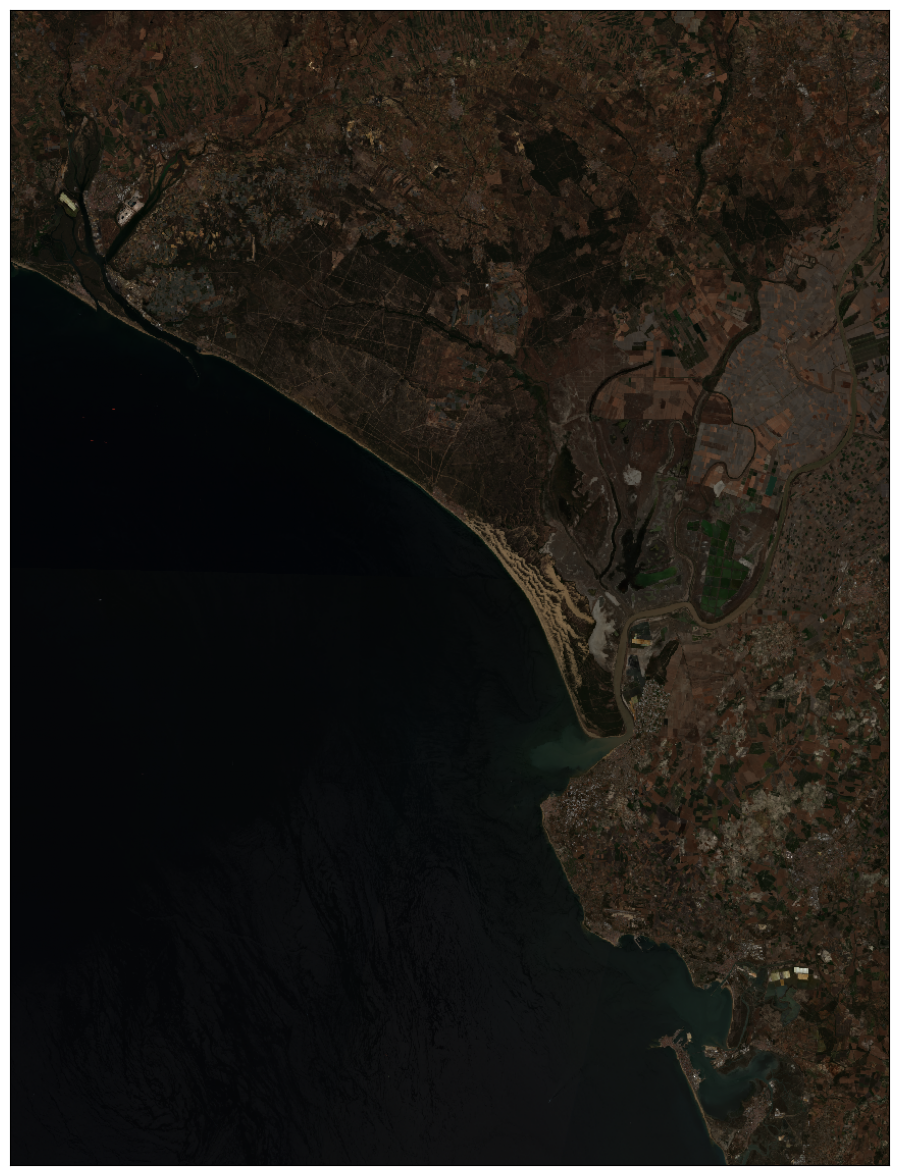

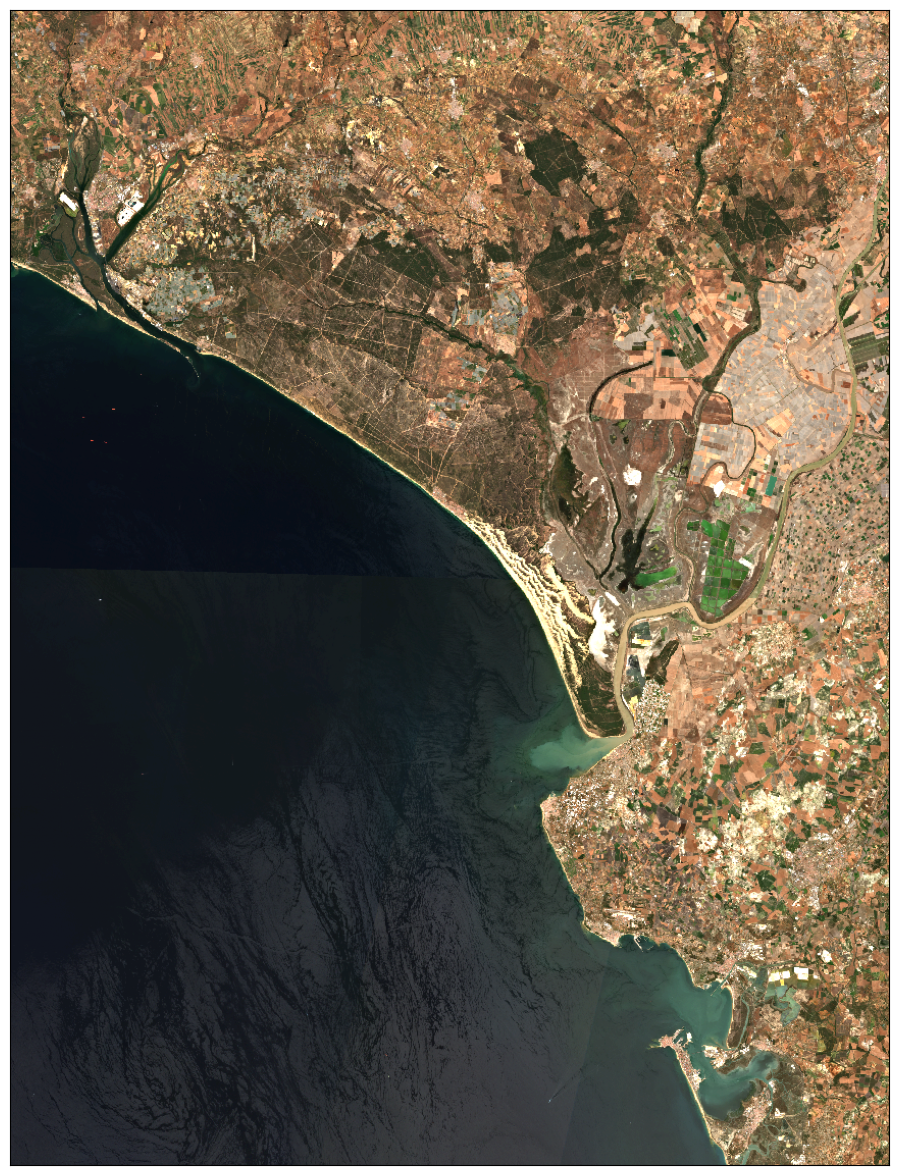

In [12]:
image = true_color_imgs[0]
print(f"Image type: {image.dtype}")
plot_image(image,  factor=1 / 255,clip_range=(0, 1))
plot_image(image, factor=3.5 / 255, clip_range=(0, 1))

In [13]:
img_sv = image

<class 'numpy.ndarray'>


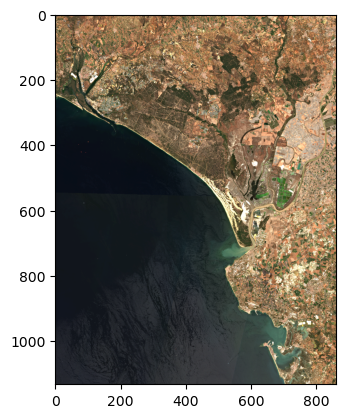

<class 'numpy.ndarray'>


In [15]:
print(type(image))
image = np.clip(np.clip(img_sv*3.5/255 , 0, 1)*255,0,255).astype(np.uint8)
plt.imshow(image)
plt.show()
print(type(image))
matplotlib.image.imsave(f'{Path.home()}/mystorage/primeraImagen.jpeg',image)